# Chapter 90: Networks, Trust, Enforcement, and Collective Behavior

This notebook reruns four of the chapter's hypothetical cases: a nonredundant acquaintance in a job search, closure as enforcement of trade credit, a bridge no one sponsors, and reputation with a bond. A few extra input values are added for comparison.

## Setup

The functions below are the calculations behind every number in this notebook. Run this cell first.

In [1]:
import math
from types import SimpleNamespace

import numpy as np
import matplotlib
import matplotlib.pyplot as plt



PALETTE = {
    "ink": "#172a3b",
    "teal": "#136f75",
    "gold": "#8f5d0f",
    "navy": "#334c72",
    "terracotta": "#a24a33",
    "olive": "#5d6a37",
    "grey": "#6b757b",
    "light": "#c9d3d6",
}


CYCLE = ["teal", "navy", "gold", "terracotta", "olive", "grey"]


LABEL_SIZE = 10.5


HOUSE_RC = {
    "font.size": 11.5,
    "axes.titlesize": 12,
    "axes.labelsize": 11.5,
    "xtick.labelsize": 10.5,
    "ytick.labelsize": 10.5,
    "legend.fontsize": 10.5,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#6b757b",
    "axes.labelcolor": "#172a3b",
    "xtick.color": "#172a3b",
    "ytick.color": "#172a3b",
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "svg.fonttype": "path",
}


def color(name_or_index):
    """Palette colour by name ('teal') or by position in the series cycle (0, 1, ...)."""
    if isinstance(name_or_index, int):
        return PALETTE[CYCLE[name_or_index % len(CYCLE)]]
    return PALETTE.get(name_or_index, name_or_index)


def tex_safe(text):
    """Escape dollar signs so Matplotlib does not read '$...$' as mathematics."""
    return str(text).replace("\\$", "$").replace("$", r"\$")


def new_figure(ncols=1, width=None, height=4.3):
    """Notebook twin of readerkit.new_figure: one panel 6.6 x 4.3 in, two panels 10.4 x 4.3 in."""
    import matplotlib.pyplot as plt

    if width is None:
        width = 6.6 if ncols == 1 else 10.4
    fig, axes = plt.subplots(1, ncols, figsize=(width, height), layout="constrained")
    for ax in (axes if ncols > 1 else [axes]):
        ax.grid(alpha=0.18)
    return fig, axes


def label(ax, x, y, text, col="ink", dx=6, dy=6, ha="left", va="bottom", box=True, size=LABEL_SIZE):
    """Direct label at data point (x, y) offset by (dx, dy) points, with a white box by default."""
    kw = {}
    if box:
        kw["bbox"] = {"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9}
    return ax.annotate(tex_safe(text), (x, y), xytext=(dx, dy), textcoords="offset points", ha=ha, va=va,
                       color=color(col), fontsize=size, **kw)


def mark(ax, x, y, text=None, col="ink", size=42, dx=6, dy=6, ha="left", va="bottom", zorder=5):
    """Filled point with an optional direct label."""
    ax.scatter([x], [y], s=size, color=color(col), zorder=zorder)
    if text:
        label(ax, x, y, text, col=col, dx=dx, dy=dy, ha=ha, va=va)


def hline(ax, y, text=None, col="grey", style="dashed", x_frac=0.02, va="bottom", lw=1.4):
    """Horizontal reference line with an optional label at the left edge."""
    ax.axhline(y, color=color(col), linestyle=style, linewidth=lw)
    if text:
        ax.annotate(tex_safe(text), (x_frac, y), xycoords=("axes fraction", "data"), xytext=(0, 4 if va == "bottom" else -4),
                    textcoords="offset points", ha="left", va=va, color=color(col), fontsize=LABEL_SIZE,
                    bbox={"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9})


def vline(ax, x, text=None, col="grey", style="dashed", y_frac=0.95, ha="left", lw=1.4):
    """Vertical reference line with an optional label near the top of the axes."""
    ax.axvline(x, color=color(col), linestyle=style, linewidth=lw)
    if text:
        ax.annotate(tex_safe(text), (x, y_frac), xycoords=("data", "axes fraction"), xytext=(5 if ha == "left" else -5, 0),
                    textcoords="offset points", ha=ha, va="top", color=color(col), fontsize=LABEL_SIZE,
                    bbox={"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9})


def bar_compare(ax, names, values, colors=None, value_labels=None, ylabel="Value", xlabel="Item", fmt=None,
                zero_line=True):
    """Labelled vertical bars, one per name; each bar carries its value label.

    ``value_labels`` gives the text over each bar (else ``fmt(v)`` or '{:,.2f}').
    Negative bars are allowed; labels go below them.
    """
    values = [float(v) for v in values]
    colors = colors or [color(i) for i in range(len(values))]
    xs = np.arange(len(values))
    ax.bar(xs, values, color=[color(c) for c in colors], width=0.6)
    ax.set_xticks(xs, names)
    lo, hi = min(0.0, min(values)), max(0.0, max(values))
    span = (hi - lo) or 1.0
    ax.set_ylim(lo - (0.14 * span if lo < 0 else 0), hi + 0.16 * span)
    for x, v, i in zip(xs, values, range(len(values))):
        text = value_labels[i] if value_labels else (fmt(v) if fmt else f"{v:,.2f}")
        ax.annotate(text, (x, v), xytext=(0, 4 if v >= 0 else -4), textcoords="offset points", ha="center",
                    va="bottom" if v >= 0 else "top", fontsize=LABEL_SIZE, color=PALETTE["ink"])
    if zero_line and lo < 0:
        ax.axhline(0, color=PALETTE["grey"], linewidth=1)
    ax.set_ylabel(ylabel)
    ax.set_xlabel(xlabel)
    return ax


def stacked_bar(ax, names, parts, part_labels, colors=None, ylabel="Value", total_marker=True, fmt=None):
    """Bars built from signed parts (one list per part), with a marker at each bar's net total.

    Positive parts stack upward from zero and negative parts downward, so a bar with a
    negative substitution part and a positive income part shows both pieces and the net.
    """
    parts = [[float(v) for v in p] for p in parts]
    n = len(names)
    xs = np.arange(n)
    colors = colors or [color(i) for i in range(len(parts))]
    pos_base, neg_base = np.zeros(n), np.zeros(n)
    for p, lab, col in zip(parts, part_labels, colors):
        p = np.array(p)
        base = np.where(p >= 0, pos_base, neg_base)
        ax.bar(xs, p, bottom=base, color=color(col), width=0.55, label=lab)
        pos_base = pos_base + np.where(p >= 0, p, 0)
        neg_base = neg_base + np.where(p < 0, p, 0)
    totals = np.sum(np.array(parts), axis=0)
    if total_marker:
        ax.scatter(xs, totals, marker="D", s=46, color=PALETTE["ink"], zorder=5)
        for x, t in zip(xs, totals):
            ax.annotate(f"net {fmt(t) if fmt else f'{t:,.2f}'}", (x, t), xytext=(14, 0), textcoords="offset points",
                        ha="left", va="center", fontsize=LABEL_SIZE,
                        bbox={"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9})
    ax.axhline(0, color=PALETTE["grey"], linewidth=1)
    ax.set_xticks(xs, names)
    ax.set_xlim(-0.6, n - 0.4 + 0.5)
    ax.set_ylabel(ylabel)
    return ax


def num(value, digits=2, comma=True):
    """Fixed-decimal string with optional thousands separators: num(1444.444) -> '1,444.44'.

    Negative zero prints as '0'. Raises ValueError on NaN or infinity, because an
    undefined value must be named in words (see ``undefined``).
    """
    value = float(value)
    if not math.isfinite(value):
        raise ValueError("non-finite value; name it with undefined(reason)")
    text = f"{value:,.{digits}f}" if comma else f"{value:.{digits}f}"
    if text.startswith("-") and float(text.replace(",", "")) == 0:
        text = text[1:]
    return text


def money(value, digits=2, comma=True):
    """Dollar amount: money(1444.444) -> '$1,444.44'; money(-480, 0) -> '-$480'."""
    text = num(value, digits, comma)
    return f"-${text[1:]}" if text.startswith("-") else f"${text}"


def pct(fraction, digits=1):
    """Percent from a fraction: pct(0.022) -> '2.2%'."""
    return f"{num(100 * float(fraction), digits)}%"


def independent_leads(probs):
    """Chance of at least one lead from independent pools: 1 - prod(1 - p).

    Principle: strength-of-weak-ties (chapter 90). Book: 1 - (1 - 0.40)(1 - 0.15) = 0.49;
    1 - 0.60 x 0.97 = 0.418.
    """
    miss = 1.0
    for p in probs:
        miss *= 1 - p
    return 1 - miss


def enforcement_threshold(p, S, gain):
    """Default is deterred when gain <= p S. Returns expected consequence pS, margin pS - gain, deterred.

    Principle: network-closure-as-an-enforcement-mechanism (chapter 90). Book: 0.20 x 1,500 = 300
    and 0.80 x 2,000 = 1,600 against a 1,000 gain (margin +600); 0.80 x 300 = 240.
    """
    ps = p * S
    return {"pS": ps, "margin": ps - gain, "deterred": gain <= ps, "tie": abs(ps - gain) < 1e-9}


def link_formation(values, cost, transfer=0.0):
    """Sponsor (first value) pays the link cost and receives a transfer from the other beneficiary.

    Principle: strategic-network-formation (chapter 90). Book: values (10, 10), cost 12: sponsor
    10 - 12 = -2, social 10 + 10 - 12 = 8; with transfer 3, sponsor 1 and B 7; cost 8 gives 2.
    Returns sponsor and other payoffs if built, social surplus and built (sponsor payoff >= 0).
    """
    sponsor = values[0] + transfer - cost
    other = sum(values[1:]) - transfer
    return {"sponsor": sponsor, "other": other, "social": sum(values) - cost, "built": sponsor >= 0}


def reputation_value(p, payment, delta, n):
    """Expected business lost after detected cheating: p x payment x (1 + delta + ... + delta^(n-1)).

    Principle: diaspora-middleman (chapter 90). Book: 0.9 x 6,000 x 3.439 = 18,570.60;
    0.4 x 6,000 x 3.439 = 8,253.60. Returns dict with factor and expected loss.
    """
    factor = sum(delta ** k for k in range(n))
    return {"factor": factor, "loss": p * payment * factor}


plt.rcParams.update(HOUSE_RC)


information = SimpleNamespace(independent_leads=independent_leads)


games = SimpleNamespace(enforcement_threshold=enforcement_threshold, link_formation=link_formation, reputation_value=reputation_value)


# The book's printed values for this chapter (inputs of the worked examples).
BV = {'strength-of-weak-ties': {'local': 0.4,
                           'see': 0.3,
                           'fwd': 0.5,
                           'contrib': 0.15,
                           'total': 0.49,
                           'overlap': 0.8,
                           'contrib_overlap': 0.03,
                           'total_overlap': 0.418},
 'network-closure-as-an-enforcement-mechanism': {'gain': 1000,
                                                 'p_iso': 0.2,
                                                 'S_iso': 1500,
                                                 'pS_iso': 300,
                                                 'p': 0.8,
                                                 'S': 2000,
                                                 'pS': 1600,
                                                 'margin': 600,
                                                 'S_small': 300,
                                                 'pS_small': 240},
 'strategic-network-formation': {'values': (10, 10),
                                 'cost': 12,
                                 'sponsor': -2,
                                 'social': 8,
                                 'cost_low': 8,
                                 'sponsor_low': 2,
                                 'transfer': 3,
                                 'sponsor_tr': 1,
                                 'other_tr': 7},
 'diaspora-middleman': {'gain': 20000,
                        'payment': 6000,
                        'n': 4,
                        'delta': 0.9,
                        'p': 0.9,
                        'loss': 18570.6,
                        'bond': 3000,
                        'bond_loss': 2700,
                        'total': 21270.6,
                        'p_low': 0.4,
                        'loss_low': 8253.6,
                        'bond_low': 1200,
                        'total_low': 9453.6},
 'constructed': {'strength-of-weak-ties': {'overlap': [0.5], 'fwd': [1.0]},
                 'network-closure-as-an-enforcement-mechanism': {'p': [0.5]},
                 'strategic-network-formation': {'cost': [16]},
                 'diaspora-middleman': {'p': [0.65], 'bond': [0, 6000]}}}


def weak_tie_picture(overlap=0.0, fwd=0.5):
    b = BV["strength-of-weak-ties"]
    contrib = b["see"] * fwd * (1 - overlap)
    total = information.independent_leads([b["local"], contrib])
    added = total - b["local"]
    fig, ax = new_figure()
    bar_compare(ax, ["Close circle only", "Plus Omar"], [b["local"], total], colors=["grey", "teal"],
                value_labels=[num(b["local"], 3), num(total, 3)], ylabel="Chance of at least one lead",
                xlabel="Lina's network")
    ax.set_ylim(0, 0.75)
    label(ax, 0.5, 0.66, f"Omar adds {num(added * 100, 1)} points", col="navy", dx=0, dy=0, ha="center", box=False)
    metrics = {"Omar's nonredundant contribution": num(contrib, 3), "Chance of a lead": num(total, 3),
               "Added by the tie": f"{num(added * 100, 1)} points"}
    steps = [f"Contribution = 0.30 x {num(fwd)} x (1 - {num(overlap)}) = {num(contrib, 3)}",
             f"P(lead) = 1 - (1 - 0.40)(1 - {num(contrib, 3)}) = 1 - 0.60 x {num(1 - contrib, 3)} = {num(total, 3)}",
             f"Added = {num(total, 3)} - 0.40 = {num(added, 3)}"]
    interp = (f"Omar sees openings with chance 0.30, forwards {pct(fwd, 0)} of them and overlaps {pct(overlap, 0)} with "
              f"Lina's circle, so his new information is 0.30 x {num(fwd)} x {num(1 - overlap)} = {num(contrib, 3)}. "
              f"Lina's chance of a lead rises from 0.40 to 1 - 0.60 x {num(1 - contrib, 3)} = {num(total, 3)}.")
    alt = f"Two bars: 0.40 with the close circle only and {num(total, 3)} with Omar's tie."
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def closure_picture(p=0.80, s=2_000):
    gain = BV["network-closure-as-an-enforcement-mechanism"]["gain"]
    r = games.enforcement_threshold(p, s, gain)
    ps, margin = r["pS"], r["margin"]
    fig, ax = new_figure()
    bar_compare(ax, ["Gain from default", "Expected consequence pS"], [gain, ps], colors=["terracotta", "teal"],
                value_labels=[money(gain, 0), money(ps, 0)], ylabel="Dollars", xlabel="Retailer's comparison")
    ax.set_ylim(0, 2_000)
    if r["tie"]:
        verdict = "the retailer is indifferent: the expected consequence exactly equals the gain"
        choice = "Indifferent (tie)"
    elif r["deterred"]:
        verdict = f"repaying is better by {money(margin, 0)}"
        choice = "Repay"
    else:
        verdict = f"default pays by {money(-margin, 0)}"
        choice = "Default"
    metrics = {"Expected consequence pS": money(ps, 0), "Margin pS - gain": money(margin, 0), "Retailer": choice}
    steps = [f"pS = {num(p)} x {num(s, 0)} = {num(ps, 0)}", f"Margin = {num(ps, 0)} - 1,000 = {num(margin, 0)}",
             f"Result: {verdict}"]
    interp = (f"Detection {num(p)} times a sanction of {num(s, 0)} dollars gives an expected consequence of "
              f"{num(p)} x {num(s, 0)} = {num(ps, 0)} dollars against the 1,000 dollar gain, so {verdict}.")
    alt = f"Two bars: the gain from default, $1,000, and the expected consequence, {money(ps, 0)}."
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def bridge_picture(cost=12, tr=0):
    values = BV["strategic-network-formation"]["values"]
    r = games.link_formation(values, cost, tr)
    fig, ax = new_figure()
    bar_compare(ax, ["A if it sponsors", "B", "Total (social)"], [r["sponsor"], r["other"], r["social"]],
                colors=["teal", "gold", "navy"], value_labels=[num(r["sponsor"], 0), num(r["other"], 0),
                                                              num(r["social"], 0)],
                ylabel="Payoff from the bridge", xlabel="Party")
    ax.set_ylim(-9, 14)
    built = r["built"]
    if built and r["social"] >= 0:
        verdict = "A sponsors the bridge, and it adds total surplus"
    elif built:
        verdict = "A sponsors the bridge even though it loses total surplus"
    elif r["social"] > 0:
        verdict = (f"no one builds the bridge although it would add {num(r['social'], 0)} units: a transfer of at "
                   f"least {num(cost - values[0], 0)} would be needed")
    else:
        verdict = "no one builds the bridge, which is also efficient"
    metrics = {"A's private payoff": num(r["sponsor"], 0), "B's payoff": num(r["other"], 0),
               "Social surplus": num(r["social"], 0), "Built": "Yes" if built else "No"}
    steps = [f"A: 10 + {num(tr, 0)} - {cost} = {num(r['sponsor'], 0)}", f"B: 10 - {num(tr, 0)} = {num(r['other'], 0)}",
             f"Social: 10 + 10 - {cost} = {num(r['social'], 0)}", f"Result: {verdict}"]
    interp = (f"At cost {cost} with a transfer of {num(tr, 0)} from B, A's payoff from sponsoring is 10 + "
              f"{num(tr, 0)} - {cost} = {num(r['sponsor'], 0)} and total surplus is 10 + 10 - {cost} = "
              f"{num(r['social'], 0)}, so {verdict}.")
    alt = (f"Three bars: A's payoff {num(r['sponsor'], 0)}, B's {num(r['other'], 0)} and total "
           f"{num(r['social'], 0)}.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def bond_picture(p=0.9, bond=3_000):
    b = BV["diaspora-middleman"]
    rep = games.reputation_value(p, b["payment"], b["delta"], b["n"])
    lost, factor = rep["loss"], rep["factor"]
    bl = p * bond
    total = lost + bl
    gain = b["gain"]
    fig, ax = new_figure()
    stacked_bar(ax, ["Cost of cheating"], [[lost], [bl]], ["expected lost business", "expected bond loss"],
                colors=["teal", "gold"], ylabel="Dollars", total_marker=False)
    hline(ax, gain, "diversion gain 20,000", col="terracotta", x_frac=0.6, va="top")
    label(ax, 0, total, f"total {num(total)}", dx=0, dy=4, ha="center")
    ax.set_xlim(-0.8, 1.6)
    ax.set_ylim(0, 30_000)
    ax.yaxis.set_major_formatter(lambda v, _: f"{v:,.0f}")
    ax.set_xlabel("Agent's comparison")
    ax.legend(loc="upper right", frameon=False)
    honest = total >= gain
    verdict = ("honest service is privately better" if total > gain else
               ("the agent is indifferent" if total == gain else "diverting the shipment pays"))
    metrics = {"Expected lost business": num(lost), "Expected bond loss": num(bl), "Total consequence": num(total),
               "Honest": "Yes" if total > gain else ("Indifferent (tie)" if total == gain else "No")}
    steps = [f"1 + 0.9 + 0.9^2 + 0.9^3 = {num(factor, 3)}",
             f"Lost business = {num(p)} x 6,000 x {num(factor, 3)} = {num(lost)}",
             f"Bond loss = {num(p)} x {num(bond, 0)} = {num(bl)}",
             f"Total = {num(lost)} + {num(bl)} = {num(total)} against 20,000: {verdict}"]
    interp = (f"With detection {num(p)}, cheating forfeits {num(p)} x 6,000 x {num(factor, 3)} = {num(lost)} of "
              f"future business plus {num(p)} x {num(bond, 0)} = {num(bl)} of bond, {num(total)} in all against a "
              f"20,000 gain, so {verdict}.")
    alt = (f"Stacked bar: expected lost business {num(lost)} and expected bond loss {num(bl)}, against a line at "
           f"the 20,000 diversion gain.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}

def show(result):
    """Draw the figure, then print the numbers, the worked steps and the reading."""
    fig, metrics, interpretation = result[0], result[1], result[2]
    extra = result[3] if len(result) > 3 else {}
    plt.show()
    width = max(len(k) for k in metrics)
    for k, v in metrics.items():
        print(f"{k:<{width}}  {v}")
    steps = extra.get("steps", []) if isinstance(extra, dict) else []
    if steps:
        print("\nWorked steps:")
        for i, s in enumerate(steps, 1):
            print(f"  {i}. {s}")
    print("\n" + interpretation)


def sweep(function, control, values, fixed, labels):
    """One line per value of one input, holding the others fixed."""
    print(" | ".join([control] + labels))
    for v in values:
        result = function(**{**fixed, control: v})
        plt.close(result[0])
        print(" | ".join([str(v)] + [str(result[1][k]) for k in labels]))


## 1. Strength of weak ties: the value of a nonredundant acquaintance

Lina's circle yields a lead with chance 0.40; Omar sees openings with chance 0.30 and forwards half.

$$0.30(0.50)=0.15, \qquad 1-(1-0.40)(1-0.15)=0.49$$

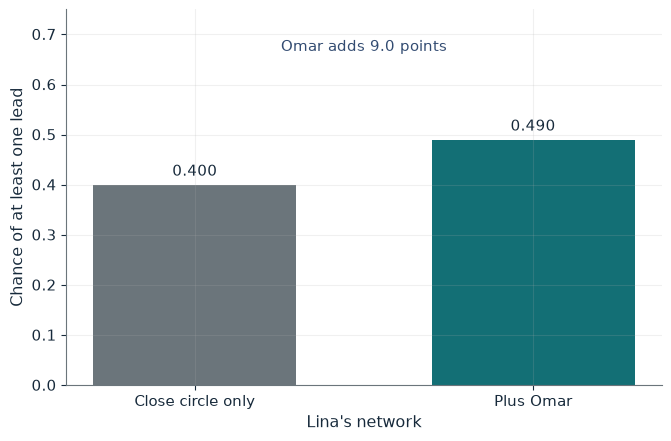

Omar's nonredundant contribution  0.150
Chance of a lead                  0.490
Added by the tie                  9.0 points

Worked steps:
  1. Contribution = 0.30 x 0.50 x (1 - 0.00) = 0.150
  2. P(lead) = 1 - (1 - 0.40)(1 - 0.150) = 1 - 0.60 x 0.850 = 0.490
  3. Added = 0.490 - 0.40 = 0.090

Omar sees openings with chance 0.30, forwards 50% of them and overlaps 0% with Lina's circle, so his new information is 0.30 x 0.50 x 1.00 = 0.150. Lina's chance of a lead rises from 0.40 to 1 - 0.60 x 0.850 = 0.490.


In [2]:
show(weak_tie_picture(overlap=0.0, fwd=0.5))

Change one input, `overlap`, and hold the others at the book's values:

In [3]:
sweep(weak_tie_picture, 'overlap', [0.0, 0.5, 0.8], {'fwd': 0.5}, ['Chance of a lead', 'Added by the tie'])

overlap | Chance of a lead | Added by the tie
0.0 | 0.490 | 9.0 points
0.5 | 0.445 | 4.5 points
0.8 | 0.418 | 1.8 points


The tie adds 9 points with no overlap, but only 1.8 points once 80 percent of Omar's leads overlap.

## 2. Network closure: enforcement of trade credit

Keeping a \$1,000 invoice is the gain; detection p and sanction S set the expected consequence.

$$d\leq p(C_{ij})S(C_{ij}), \qquad 0.80(\$2{,}000)=\$1{,}600$$

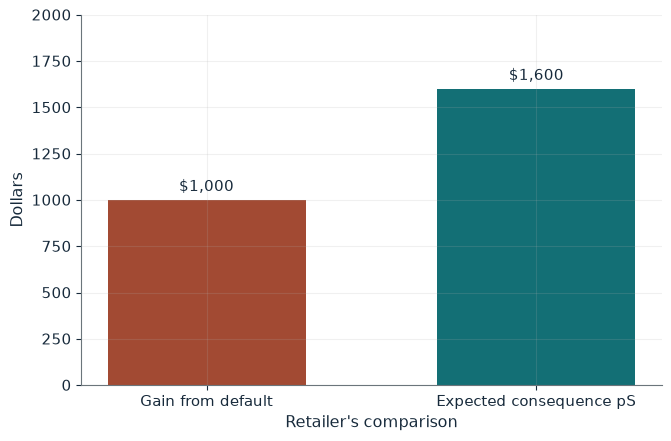

Expected consequence pS  $1,600
Margin pS - gain         $600
Retailer                 Repay

Worked steps:
  1. pS = 0.80 x 2,000 = 1,600
  2. Margin = 1,600 - 1,000 = 600
  3. Result: repaying is better by $600

Detection 0.80 times a sanction of 2,000 dollars gives an expected consequence of 0.80 x 2,000 = 1,600 dollars against the 1,000 dollar gain, so repaying is better by $600.


In [4]:
show(closure_picture(p=0.80, s=2_000))

Change one input, `p`, and hold the others at the book's values:

In [5]:
sweep(closure_picture, 'p', [0.2, 0.5, 0.8], {'s': 2000}, ['Expected consequence pS', 'Retailer'])

p | Expected consequence pS | Retailer
0.2 | $400 | Default
0.5 | $1,000 | Indifferent (tie)
0.8 | $1,600 | Repay


At p = 0.80 repayment wins by \$600; at 0.50 the retailer is exactly indifferent.

## 3. Strategic network formation: the bridge nobody builds

The bridge costs 12 and is worth 10 to A and 10 to B.

$$10-12=-2, \qquad 10+10-12=8$$

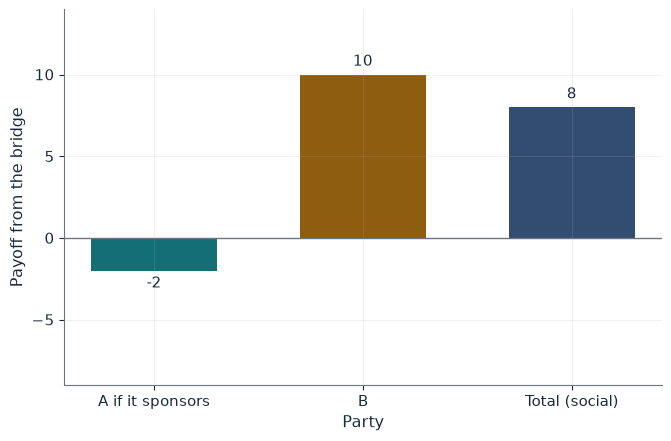

A's private payoff  -2
B's payoff          10
Social surplus      8
Built               No

Worked steps:
  1. A: 10 + 0 - 12 = -2
  2. B: 10 - 0 = 10
  3. Social: 10 + 10 - 12 = 8
  4. Result: no one builds the bridge although it would add 8 units: a transfer of at least 2 would be needed

At cost 12 with a transfer of 0 from B, A's payoff from sponsoring is 10 + 0 - 12 = -2 and total surplus is 10 + 10 - 12 = 8, so no one builds the bridge although it would add 8 units: a transfer of at least 2 would be needed.


In [6]:
show(bridge_picture(cost=12, tr=0))

Change one input, `tr`, and hold the others at the book's values:

In [7]:
sweep(bridge_picture, 'tr', [0, 3], {'cost': 12}, ["A's private payoff", 'Social surplus', 'Built'])

tr | A's private payoff | Social surplus | Built
0 | -2 | 8 | No
3 | 1 | 8 | Yes


Without a transfer A loses 2, so no one builds; a transfer of 3 from B makes A's payoff 1.

## 4. Diaspora networks: reputation, bonds, and the honest agent

Diverting pays 20,000; honesty keeps four 6,000 opportunities discounted at 0.9.

$$0.9(6{,}000)(1+0.9+0.9^2+0.9^3)=18{,}570.60$$

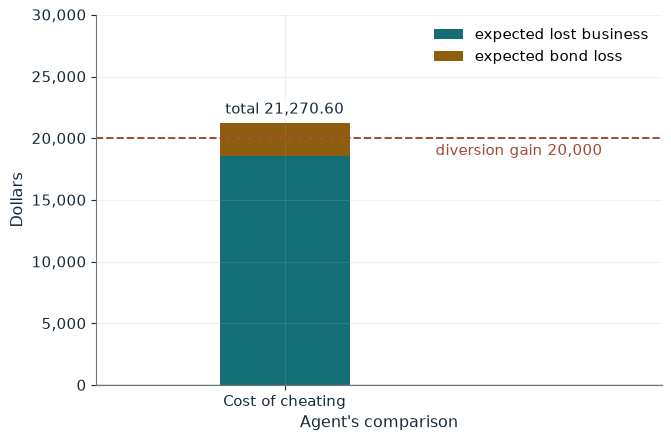

Expected lost business  18,570.60
Expected bond loss      2,700.00
Total consequence       21,270.60
Honest                  Yes

Worked steps:
  1. 1 + 0.9 + 0.9^2 + 0.9^3 = 3.439
  2. Lost business = 0.90 x 6,000 x 3.439 = 18,570.60
  3. Bond loss = 0.90 x 3,000 = 2,700.00
  4. Total = 18,570.60 + 2,700.00 = 21,270.60 against 20,000: honest service is privately better

With detection 0.90, cheating forfeits 0.90 x 6,000 x 3.439 = 18,570.60 of future business plus 0.90 x 3,000 = 2,700.00 of bond, 21,270.60 in all against a 20,000 gain, so honest service is privately better.


In [8]:
show(bond_picture(p=0.9, bond=3_000))

Change one input, `p`, and hold the others at the book's values:

In [9]:
sweep(bond_picture, 'p', [0.4, 0.65, 0.9], {'bond': 3000}, ['Total consequence', 'Honest'])

p | Total consequence | Honest
0.4 | 9,453.60 | No
0.65 | 15,362.10 | No
0.9 | 21,270.60 | Yes


With detection 0.9 and the bond the total is 21,270.60, enough; at 0.4 it falls to 9,453.60.

## Your numbers

Replace the inputs below with your own and run the cell. Every function above accepts any value in the range its section describes.

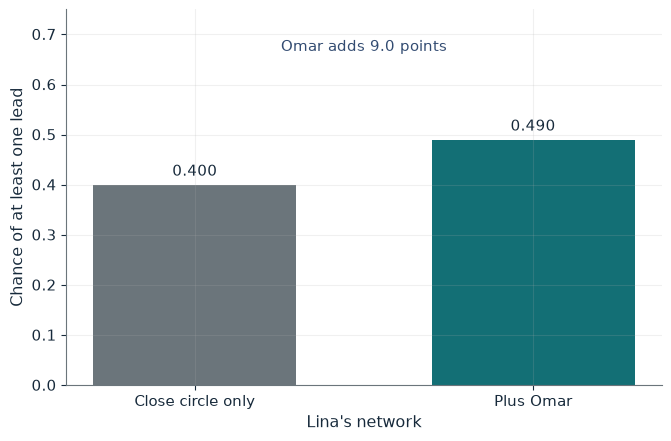

Omar's nonredundant contribution  0.150
Chance of a lead                  0.490
Added by the tie                  9.0 points

Worked steps:
  1. Contribution = 0.30 x 0.50 x (1 - 0.00) = 0.150
  2. P(lead) = 1 - (1 - 0.40)(1 - 0.150) = 1 - 0.60 x 0.850 = 0.490
  3. Added = 0.490 - 0.40 = 0.090

Omar sees openings with chance 0.30, forwards 50% of them and overlaps 0% with Lina's circle, so his new information is 0.30 x 0.50 x 1.00 = 0.150. Lina's chance of a lead rises from 0.40 to 1 - 0.60 x 0.850 = 0.490.


In [10]:
show(weak_tie_picture(overlap=0.0, fwd=0.5))

## Practice

**1.** With overlap 0 and forwarding 1.0, what is the chance of a lead?

<details><summary>Answer</summary>

Contribution 0.30, so 1 - 0.60 x 0.70 = 0.58.

</details>

**2.** At p = 0.20 and S = 2,000, is default deterred?

<details><summary>Answer</summary>

pS = 400 < 1,000, so no.

</details>

**3.** At cost 8 with no transfer, is the bridge built?

<details><summary>Answer</summary>

A gets 10 - 8 = 2 > 0, so yes; social surplus is 12.

</details>